# 02 Frequency modelling

Exposure-aware claim-count models. **Fitted on train, compared on the validation split only.** The test split is never read here.

Models: constant rate, Poisson GLM (log-exposure offset), Negative Binomial GLM, LightGBM Poisson (exposure as a log offset through the initial score).

In [1]:
import sys, warnings
sys.path.insert(0, "..")            # make the project's src/ package importable from notebooks/
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils.config import ROOT, load_config
cfg = load_config()
proc = ROOT / cfg["paths"]["processed_dir"]
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
from src.evaluation.metrics import frequency_summary, gini, lift_table
from src.models.frequency import ConstantRateBaseline, LightGBMFrequency, NegBinGLM, PoissonGLM
train = pd.read_parquet(proc / "policies_train.parquet")
val = pd.read_parquet(proc / "policies_val.parquet")
print(len(train), len(val))

406794 135598


In [2]:
glm = PoissonGLM(cfg).fit(train)
nb_glm = NegBinGLM(cfg).fit(train)
lgbm = LightGBMFrequency(cfg).fit(train, val)       # validation is used for early stopping only
models = {"constant_rate": ConstantRateBaseline().fit(train), "poisson_glm": glm, "negbin_glm": nb_glm, "lightgbm_poisson": lgbm}
print(f"Poisson GLM Pearson dispersion: {glm.dispersion():.2f}; NB alpha: {nb_glm.alpha_:.2f}; LightGBM trees: {lgbm.best_iteration_}")

Poisson GLM Pearson dispersion: 1.89; NB alpha: 1.05; LightGBM trees: 534


**Overdispersion check:** a Pearson dispersion clearly above 1 means the Poisson variance assumption is too tight. The Negative Binomial model accounts for it but gives almost the same point predictions, so it mainly matters for uncertainty, not ranking.

In [3]:
y, e = val["ClaimNb"].to_numpy(), val["Exposure"].to_numpy()
rows = []
for name, m in models.items():
    mu = m.predict_counts(val)
    s = frequency_summary(y, mu, e); s["gini"] = gini(y, mu, e)
    rows.append({"model": name, **s})
res = pd.DataFrame(rows).set_index("model"); res.round(4)

,poisson_deviance,mae_counts,actual_freq,predicted_freq,actual_to_predicted,gini
model,,,,,,
constant_rate,0.2524,0.0741,0.0734,0.0738,0.9940,-0.0033
poisson_glm,0.2395,0.0725,0.0734,0.0737,0.9954,0.3027
negbin_glm,0.2396,0.0727,0.0734,0.0741,0.9904,0.3031
lightgbm_poisson,0.2338,0.0717,0.0734,0.0736,0.9972,0.3392


**Reading this:** lower Poisson deviance and higher Gini are better. LightGBM is best on validation; a Gini far above the constant model's ~0 shows genuine risk-ranking. This is model *selection* data, not final performance (see notebook 04).

## Calibration and lift (validation)

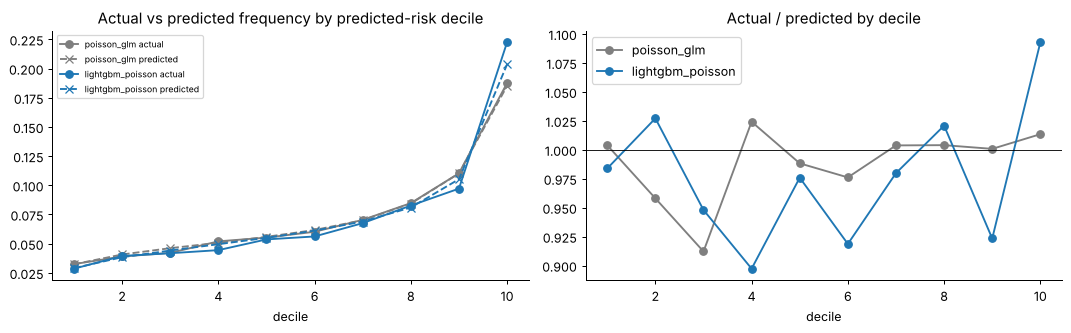

,bin,policies,exposure,claims,expected,actual_freq,predicted_freq,actual_to_predicted,lift_vs_mean
0,1,10293,7174.755,205.0,208.373,0.029,0.029,0.984,0.389
1,2,11107,7174.830,283.0,275.541,0.039,0.038,1.027,0.537
2,3,11821,7174.388,300.0,316.464,0.042,0.044,0.948,0.570
3,4,12708,7175.297,319.0,355.518,0.044,0.050,0.897,0.606
4,5,13502,7175.169,385.0,394.534,0.054,0.055,0.976,0.731
5,6,14273,7174.456,403.0,438.684,0.056,0.061,0.919,0.765
6,7,14768,7175.512,485.0,495.016,0.068,0.069,0.980,0.921
7,8,15219,7174.965,593.0,580.923,0.083,0.081,1.021,1.126
8,9,15919,7174.963,697.0,754.861,0.097,0.105,0.923,1.324
9,10,15988,7175.066,1596.0,1460.610,0.222,0.204,1.093,3.031


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name, c in (("poisson_glm", "tab:gray"), ("lightgbm_poisson", "tab:blue")):
    lt = lift_table(y, models[name].predict_counts(val), e, 10)
    ax[0].plot(lt["bin"], lt["actual_freq"], "o-", color=c, label=f"{name} actual")
    ax[0].plot(lt["bin"], lt["predicted_freq"], "x--", color=c, label=f"{name} predicted")
    ax[1].plot(lt["bin"], lt["actual_to_predicted"], "o-", color=c, label=name)
ax[0].set_title("Actual vs predicted frequency by predicted-risk decile"); ax[0].set_xlabel("decile"); ax[0].legend(fontsize=7)
ax[1].axhline(1, color="k", lw=0.7); ax[1].set_title("Actual / predicted by decile"); ax[1].set_xlabel("decile"); ax[1].legend()
plt.tight_layout(); plt.show()
lift_table(y, models["lightgbm_poisson"].predict_counts(val), e, 10).round(3)

**Pricing meaning:** the highest-risk decile has roughly three times the portfolio claim frequency and the lowest about 0.4 times, with actual close to predicted across deciles. Decile ratios are noisy where claim counts are small.

## Why a GLM baseline matters
The Poisson GLM is transparent, regulator-friendly and gives auditable rating relativities; gradient boosting is only worth its extra complexity if it improves held-out performance. Here LightGBM improves deviance and ranking, but the cost is lower interpretability (see SHAP in `scripts/explain_models.py`).